# Self-Healing Machine Learning (SHML)

Automated Failure Detection, Diagnosis, Recovery,
and Safety Validation for Credit-Default Prediction


# Phase C — Controlled Missingness and Recovery

## Research Objective

Evaluate whether SHML's existing median-imputation
strategy maintains or improves predictive performance
compared with a predefined zero-imputation benchmark.

## Research Hypotheses

H1: Increasing BILL_AMT1 missingness produces measurable
predictive degradation under at least some conditions.

H2: Recovery effectiveness differs between imputation
strategies.

H4: The magnitude of performance changes depends on
missingness severity.

## Experimental Configuration

- Dataset: UCI Default of Credit Card Clients
- Model: Existing Logistic Regression baseline
- Corrupted feature: BILL_AMT1 only
- Missingness: 0%, 5%, 15%, 30%, 60%
- Random seed: 42 for the initial experiment
- Classification threshold: 0.50
- Healthy reference: Uncorrupted validation data
- Benchmark: Zero imputation
- SHML recovery: Training-median imputation
- Evaluation: F1, precision, recall, accuracy, ROC-AUC

## Experimental Controls

The model, training data, validation observations,
random missingness masks, and classification threshold
remain fixed between recovery strategies.

The test dataset remains untouched.

This initial experiment is exploratory. Statistical
validation across additional seeds follows in Phase D.


In [1]:

import numpy as np


def inject_bill_amt1_missingness(
    X_batch,
    missingness_rate,
    seed=42
):
    """
    Inject MCAR missingness into BILL_AMT1 only.

    Returns:
        corrupted DataFrame
        Boolean mask of modified rows
    """

    if not 0 <= missingness_rate <= 1:
        raise ValueError(
            "Missingness rate must be between 0 and 1."
        )

    if "BILL_AMT1" not in X_batch.columns:
        raise ValueError("BILL_AMT1 is missing.")

    X_corrupted = X_batch.copy(deep=True)

    rng = np.random.default_rng(seed)

    n_missing = int(
        len(X_corrupted) * missingness_rate
    )

    selected_positions = rng.choice(
        len(X_corrupted),
        size=n_missing,
        replace=False
    )

    mask = np.zeros(
        len(X_corrupted),
        dtype=bool
    )

    mask[selected_positions] = True

    X_corrupted.iloc[
        selected_positions,
        X_corrupted.columns.get_loc("BILL_AMT1")
    ] = np.nan

    return X_corrupted, mask


In [4]:
import pandas as pd

# Lightweight function test.
# No model training or dataset loading needed.
sample = pd.DataFrame({
    "BILL_AMT1": range(100),
    "BILL_AMT2": range(100, 200)
})

corrupted, mask = inject_bill_amt1_missingness(
    sample,
    missingness_rate=0.15,
    seed=42
)

assert corrupted["BILL_AMT1"].isna().sum() == 15
assert corrupted["BILL_AMT2"].equals(sample["BILL_AMT2"])
assert sample.isna().sum().sum() == 0
assert mask.sum() == 15

print("Phase C missingness injection test passed!")

Phase C missingness injection test passed!


In [5]:

from src.detection import detect_feature_missingness
from src.diagnosis import diagnose_failure
from src.recovery import recover_missingness
from src.evaluation import evaluate_model
from src.safety import evaluate_recovery_safety


def compare_recovery_strategies(
    X_val,
    y_val,
    X_train,
    baseline_model,
    scaler,
    missingness_rate,
    seed=42
):
    """
    Compare a zero-fill benchmark with SHML median recovery.

    Reuses the existing trained model and SHML modules.
    """

    # 1. Inject missingness
    X_corrupted, mask = inject_bill_amt1_missingness(
        X_val,
        missingness_rate,
        seed
    )

    # 2. Healthy reference
    healthy_metrics = evaluate_model(
        X_batch=X_val,
        y_true=y_val,
        model=baseline_model,
        scaler=scaler
    )

    # 3. Zero-imputation benchmark
    X_zero = X_corrupted.copy(deep=True)
    X_zero["BILL_AMT1"] = (
        X_zero["BILL_AMT1"].fillna(0)
    )

    zero_metrics = evaluate_model(
        X_batch=X_zero,
        y_true=y_val,
        model=baseline_model,
        scaler=scaler
    )

    # 4. Existing SHML detection
    detection = detect_feature_missingness(
        X_batch=X_corrupted,
        feature="BILL_AMT1",
        reference_missingness=0.0,
        threshold=0.05
    )

    # 5. Existing SHML diagnosis
    diagnosis = diagnose_failure(detection)

    # 6. Existing SHML recovery
    training_median = X_train["BILL_AMT1"].median()

    X_recovered, recovery_log = recover_missingness(
        X_batch=X_corrupted,
        diagnosis=diagnosis,
        training_median=training_median
    )

    # 7. Evaluate SHML recovery
    recovered_metrics = evaluate_model(
        X_batch=X_recovered,
        y_true=y_val,
        model=baseline_model,
        scaler=scaler
    )

    # 8. Verify recovery integrity
    integrity_passed = (
        X_recovered.isna().sum().sum() == 0
        and X_recovered.shape == X_corrupted.shape
        and X_recovered.columns.equals(X_corrupted.columns)
        and X_recovered.loc[
            ~mask, "BILL_AMT1"
        ].equals(
            X_corrupted.loc[~mask, "BILL_AMT1"]
        )
        and X_recovered.drop(
            columns=["BILL_AMT1"]
        ).equals(
            X_corrupted.drop(columns=["BILL_AMT1"])
        )
        and (
            X_recovered.loc[mask, "BILL_AMT1"]
            == training_median
        ).all()
    )

    # 9. Existing SHML safety mechanism
    safety = evaluate_recovery_safety(
        recovered_metrics=recovered_metrics,
        healthy_metrics=healthy_metrics,
        data_integrity_passed=integrity_passed,
        max_f1_loss=0.10,
        max_recall_loss=0.10
    )

    # 10. Collect paired results
    return {
        "Missingness": missingness_rate,
        "Seed": seed,
        "Values_Missing": int(mask.sum()),
        "Detected": detection["failure_detected"],
        "Healthy_F1": healthy_metrics["f1"],
        "Zero_F1": zero_metrics["f1"],
        "SHML_F1": recovered_metrics["f1"],
        "Zero_Recall": zero_metrics["recall"],
        "SHML_Recall": recovered_metrics["recall"],
        "Zero_ROC_AUC": zero_metrics["roc_auc"],
        "SHML_ROC_AUC": recovered_metrics["roc_auc"],
        "F1_Improvement": (
            recovered_metrics["f1"] -
            zero_metrics["f1"]
        ),
        "Integrity_Passed": integrity_passed,
        "Safety_Decision": safety["decision"],
        "Safety_Reason": safety["reason"]
    }


In [10]:

from pathlib import Path
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Locate project root
cwd = Path.cwd().resolve()

PROJECT_ROOT = next(
    p for p in (cwd, *cwd.parents)
    if (p / "src" / "run_pipeline.py").exists()
)

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "working"
    / "default of credit card clients.xls"
)

# Load original dataset
df = pd.read_excel(
    DATA_PATH,
    header=1,
    engine="xlrd"
)

target = "default payment next month"

X = df.drop(columns=["ID", target])
y = df[target]

# Reuse original stratified splits
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Original preprocessing and model
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

baseline_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

baseline_model.fit(X_train_scaled, y_train)

print("Existing SHML baseline initialized.")
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))
print(
    "Training median:",
    X_train["BILL_AMT1"].median()
)


Existing SHML baseline initialized.
Training: 21000
Validation: 4500
Testing: 4500
Training median: 22225.5


In [11]:
missingness_levels = [0.00, 0.05, 0.15, 0.30, 0.60]

experiment_results = []

for rate in missingness_levels:
    result = compare_recovery_strategies(
        X_val=X_val,
        y_val=y_val,
        X_train=X_train,
        baseline_model=baseline_model,
        scaler=scaler,
        missingness_rate=rate,
        seed=42
    )

    experiment_results.append(result)

results_df = pd.DataFrame(experiment_results)

display(results_df.round(6))

,Missingness,Seed,Values_Missing,Detected,Healthy_F1,Zero_F1,SHML_F1,Zero_Recall,SHML_Recall,Zero_ROC_AUC,SHML_ROC_AUC,F1_Improvement,Integrity_Passed,Safety_Decision,Safety_Reason
0,0.00,42,0,False,0.356983,0.356983,0.356983,0.240201,0.240201,0.713025,0.713025,0.000000,True,ACCEPT,All checks passed
1,0.05,42,225,False,0.356983,0.361338,0.358898,0.244221,0.242211,0.713555,0.713210,-0.002440,True,ACCEPT,All checks passed
2,0.15,42,675,True,0.356983,0.366446,0.360947,0.250251,0.245226,0.708272,0.708958,-0.005499,True,ACCEPT,All checks passed
3,0.30,42,1350,True,0.356983,0.384116,0.373723,0.267337,0.257286,0.710521,0.711135,-0.010393,True,ACCEPT,All checks passed
4,0.60,42,2700,True,0.356983,0.398017,0.384949,0.282412,0.267337,0.704881,0.706199,-0.013068,True,ACCEPT,All checks passed



### Phase C — Initial Experimental Findings

Controlled BILL_AMT1 missingness was evaluated at
0%, 5%, 15%, 30%, and 60% using random seed 42.

Two strategies were compared:
1. Zero imputation (benchmark)
2. Training-median imputation (existing SHML recovery)

#### Finding C.1 — F1 Performance

Both strategies maintained or exceeded healthy
baseline F1 at every tested missingness level.

Zero imputation outperformed SHML median imputation
in F1 at every nonzero missingness level.

This does not support the superiority of median
imputation under the current configuration.

#### Finding C.2 — ROC-AUC Performance

At 60% missingness, ROC-AUC decreased from
0.713025 (healthy) to:

- Zero imputation: 0.704881
- SHML median imputation: 0.706199

Thus, increasing F1 did not necessarily correspond
to improved discrimination across thresholds.

#### Finding C.3 — Safety Decisions

The existing safety mechanism accepted every
SHML recovery candidate.

These decisions were consistent with the configured
F1, recall, and data-integrity requirements.

However, the safety mechanism does not compare
recovery candidates against alternative strategies.

#### Research Limitations

- Results currently use only random seed 42.
- Zero imputation is a benchmark intervention,
  not an untreated corrupted-data condition.
- Statistical significance has not been assessed.
- Alternative imputation strategies remain untested.
- Results do not establish diagnosis-guided
  recovery superiority.

These findings are preliminary and require
repeated-seed validation.


In [12]:

# Phase C — Step 4: Repeated Injection Seeds

import pandas as pd

seeds = range(20)
missingness_levels = [0.00, 0.05, 0.15, 0.30, 0.60]

repeated_results = []

for seed in seeds:
    for rate in missingness_levels:
        result = compare_recovery_strategies(
            X_val=X_val,
            y_val=y_val,
            X_train=X_train,
            baseline_model=baseline_model,
            scaler=scaler,
            missingness_rate=rate,
            seed=seed
        )
        repeated_results.append(result)

repeated_df = pd.DataFrame(repeated_results)

summary_df = (
    repeated_df
    .groupby("Missingness")
    .agg(
        Zero_F1_Mean=("Zero_F1", "mean"),
        SHML_F1_Mean=("SHML_F1", "mean"),
        F1_Difference_Mean=("F1_Improvement", "mean"),
        F1_Difference_SD=("F1_Improvement", "std"),
        Zero_AUC_Mean=("Zero_ROC_AUC", "mean"),
        SHML_AUC_Mean=("SHML_ROC_AUC", "mean")
    )
    .reset_index()
)

display(summary_df.round(6))


,Missingness,Zero_F1_Mean,SHML_F1_Mean,F1_Difference_Mean,F1_Difference_SD,Zero_AUC_Mean,SHML_AUC_Mean
0,0.00,0.356983,0.356983,0.000000,0.000000,0.713025,0.713025
1,0.05,0.360792,0.359251,-0.001541,0.001893,0.711718,0.712009
2,0.15,0.368320,0.364761,-0.003559,0.002160,0.710679,0.711232
3,0.30,0.377667,0.368637,-0.009030,0.003366,0.708555,0.709558
4,0.60,0.397203,0.382537,-0.014666,0.003712,0.704121,0.705421


In [14]:

# Phase C — Step 5: Paired 95% Confidence Intervals

import numpy as np
import pandas as pd
from scipy import stats

ci_results = []

for rate, group in repeated_df.groupby("Missingness"):

    # Paired difference for each injection seed
    differences = group["F1_Improvement"].to_numpy()

    n = len(differences)
    mean_diff = differences.mean()
    sd = differences.std(ddof=1)

    if np.isclose(sd, 0):
        ci_lower = mean_diff
        ci_upper = mean_diff
    else:
        se = sd / np.sqrt(n)

        margin = stats.t.ppf(
            0.975,
            df=n - 1
        ) * se

        ci_lower = mean_diff - margin
        ci_upper = mean_diff + margin

    ci_results.append({
        "Missingness": rate,
        "N_Seeds": n,
        "Mean_F1_Difference": mean_diff,
        "CI_Lower": ci_lower,
        "CI_Upper": ci_upper,
        "Seeds_SHML_Better": int(
            (differences > 0).sum()
        ),
        "Seeds_Zero_Better": int(
            (differences < 0).sum()
        ),
        "Seeds_Tied": int(
            (differences == 0).sum()
        )
    })

ci_df = pd.DataFrame(ci_results)

display(ci_df.round(6))


,Missingness,N_Seeds,Mean_F1_Difference,CI_Lower,CI_Upper,Seeds_SHML_Better,Seeds_Zero_Better,Seeds_Tied
0,0.00,20,0.000000,0.000000,0.000000,0,0,20
1,0.05,20,-0.001541,-0.002427,-0.000655,6,13,1
2,0.15,20,-0.003559,-0.004570,-0.002548,1,19,0
3,0.30,20,-0.009030,-0.010605,-0.007454,0,20,0
4,0.60,20,-0.014666,-0.016403,-0.012929,0,20,0



### Observation C.4 — Repeated Missingness Experiments

The recovery comparison was repeated using 20 random
missingness injection seeds.

Across all nonzero missingness levels, zero imputation
achieved a higher mean F1-score than SHML
training-median imputation.

The mean F1 difference (SHML minus zero) became
more negative as missingness increased:

- 5%:  -0.001541
- 15%: -0.003559
- 30%: -0.009030
- 60%: -0.014666

However, SHML median imputation achieved a slightly
higher mean ROC-AUC at each nonzero missingness level.

This demonstrates a trade-off between F1 performance
at the fixed classification threshold and overall
ranking discrimination.

The results suggest that the existing SHML recovery
strategy should not automatically be considered
superior to simple benchmark imputation.

Uncertainty analysis and additional recovery
strategies remain necessary.



### Observation C.5 — Paired Statistical Validation

Twenty controlled missingness experiments were performed
for each severity level using different random seeds.

The comparison was paired: both imputation strategies
used identical missingness masks within each seed.

#### Main Findings

At all nonzero missingness levels, zero imputation
achieved a higher mean F1-score than the existing
SHML median-imputation strategy.

At 60% missingness:
- Mean F1 difference (SHML - Zero): -0.014666
- 95% interval: [-0.016403, -0.012929]
- Zero imputation outperformed SHML in 20/20 seeds.

All nonzero-missingness intervals excluded zero.

#### Interpretation

The existing SHML median-imputation strategy does not
demonstrate superior F1 performance against the
zero-imputation benchmark.

The observed difference generally becomes larger
as missingness severity increases.

These findings support investigating alternative
recovery strategies rather than assuming that
median imputation is the optimal correction.

#### Statistical Limitations

The confidence intervals characterize variability
across missingness injections for a fixed model and
validation dataset.

They do not establish population-level uncertainty
or generalization to unseen datasets.

Results should be interpreted as conditional on
the experimental configuration.



### Observation C.5 — Paired Statistical Validation

Twenty controlled missingness experiments were performed
for each severity level using different random seeds.

The comparison was paired: both imputation strategies
used identical missingness masks within each seed.

#### Main Findings

At all nonzero missingness levels, zero imputation
achieved a higher mean F1-score than the existing
SHML median-imputation strategy.

At 60% missingness:
- Mean F1 difference (SHML - Zero): -0.014666
- 95% interval: [-0.016403, -0.012929]
- Zero imputation outperformed SHML in 20/20 seeds.

All nonzero-missingness intervals excluded zero.

#### Interpretation

The existing SHML median-imputation strategy does not
demonstrate superior F1 performance against the
zero-imputation benchmark.

The observed difference generally becomes larger
as missingness severity increases.

These findings support investigating alternative
recovery strategies rather than assuming that
median imputation is the optimal correction.

#### Statistical Limitations

The confidence intervals characterize variability
across missingness injections for a fixed model and
validation dataset.

They do not establish population-level uncertainty
or generalization to unseen datasets.

Results should be interpreted as conditional on
the experimental configuration.


In [17]:
from pathlib import Path

cwd = Path.cwd().resolve()

PROJECT_ROOT = next(
    p for p in (cwd, *cwd.parents)
    if (p / "src" / "run_pipeline.py").exists()
)

FIGURES_DIR = (
    PROJECT_ROOT
    / "results"
    / "research"
    / "bill_amt1"
    / "figures"
)

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Figures will be saved to:")
print(FIGURES_DIR)

Figures will be saved to:
/Users/divya/Desktop/School/IU/GitStuff/SHML/results/research/bill_amt1/figures


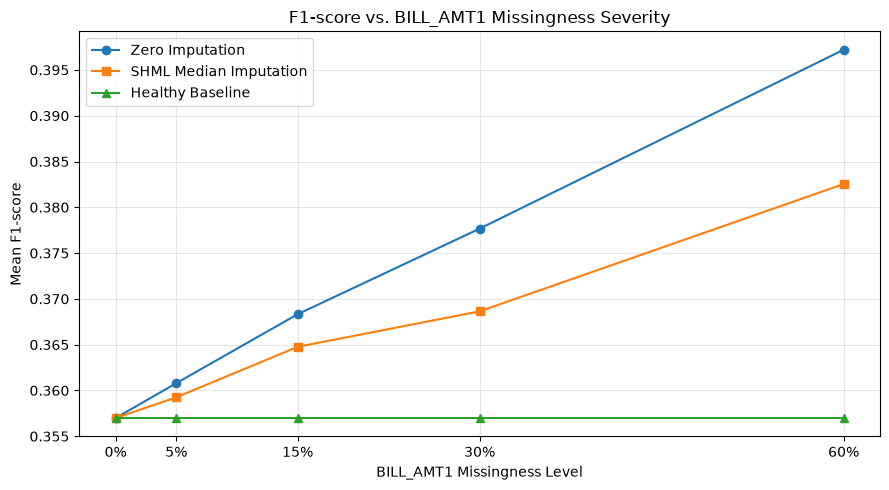

Saved: /Users/divya/Desktop/School/IU/GitStuff/SHML/results/research/bill_amt1/figures/f1_vs_missingness.png


In [18]:
import matplotlib.pyplot as plt
import numpy as np

# Copy and sort for safety
plot_df = summary_df.copy().sort_values("Missingness")

x = plot_df["Missingness"].to_numpy()
x_labels = [f"{int(rate * 100)}%" for rate in x]

# Healthy baseline F1
healthy_f1 = 0.356983

plt.figure(figsize=(9, 5))

plt.plot(x, plot_df["Zero_F1_Mean"], marker="o", label="Zero Imputation")
plt.plot(x, plot_df["SHML_F1_Mean"], marker="s", label="SHML Median Imputation")
plt.plot(x, [healthy_f1] * len(x), marker="^", label="Healthy Baseline")

plt.xticks(x, x_labels)
plt.xlabel("BILL_AMT1 Missingness Level")
plt.ylabel("Mean F1-score")
plt.title("F1-score vs. BILL_AMT1 Missingness Severity")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

f1_path = FIGURES_DIR / "f1_vs_missingness.png"
plt.savefig(f1_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", f1_path)

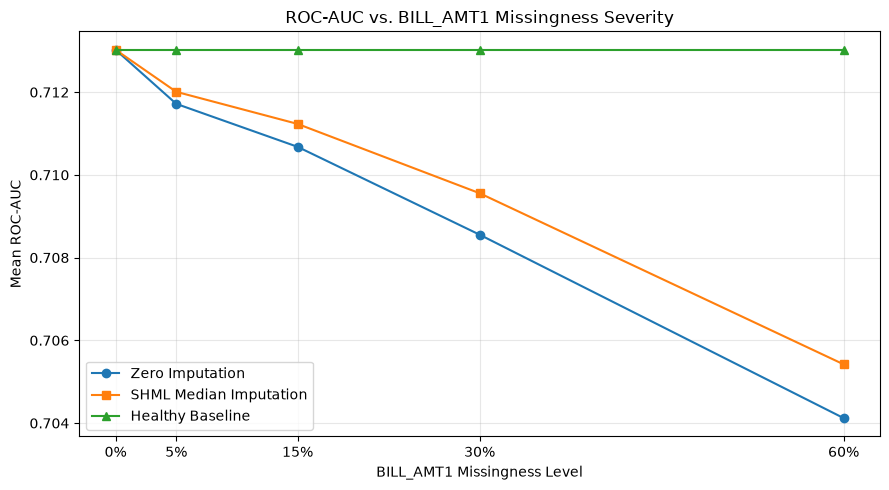

Saved: /Users/divya/Desktop/School/IU/GitStuff/SHML/results/research/bill_amt1/figures/roc_auc_vs_missingness.png


In [19]:
plot_df = summary_df.copy().sort_values("Missingness")

x = plot_df["Missingness"].to_numpy()
x_labels = [f"{int(rate * 100)}%" for rate in x]

healthy_auc = 0.713025

plt.figure(figsize=(9, 5))

plt.plot(x, plot_df["Zero_AUC_Mean"], marker="o", label="Zero Imputation")
plt.plot(x, plot_df["SHML_AUC_Mean"], marker="s", label="SHML Median Imputation")
plt.plot(x, [healthy_auc] * len(x), marker="^", label="Healthy Baseline")

plt.xticks(x, x_labels)
plt.xlabel("BILL_AMT1 Missingness Level")
plt.ylabel("Mean ROC-AUC")
plt.title("ROC-AUC vs. BILL_AMT1 Missingness Severity")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

auc_path = FIGURES_DIR / "roc_auc_vs_missingness.png"
plt.savefig(auc_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", auc_path)

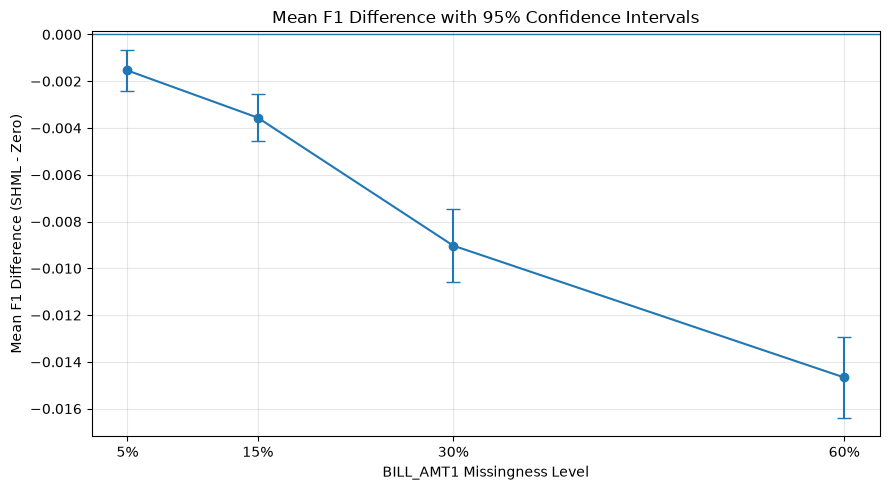

Saved: /Users/divya/Desktop/School/IU/GitStuff/SHML/results/research/bill_amt1/figures/recovery_confidence_intervals.png


In [20]:
plot_ci = ci_df.copy().sort_values("Missingness")

# Optional: exclude 0% since it is always exactly zero
plot_ci_nonzero = plot_ci[plot_ci["Missingness"] > 0].copy()

x = plot_ci_nonzero["Missingness"].to_numpy()
x_labels = [f"{int(rate * 100)}%" for rate in x]

mean_diff = plot_ci_nonzero["Mean_F1_Difference"].to_numpy()
ci_lower = plot_ci_nonzero["CI_Lower"].to_numpy()
ci_upper = plot_ci_nonzero["CI_Upper"].to_numpy()

# Convert CI bounds into matplotlib yerr format
yerr = np.vstack([
    mean_diff - ci_lower,
    ci_upper - mean_diff
])

plt.figure(figsize=(9, 5))

plt.errorbar(
    x,
    mean_diff,
    yerr=yerr,
    fmt="o-",
    capsize=5
)

plt.axhline(0, linewidth=1)

plt.xticks(x, x_labels)
plt.xlabel("BILL_AMT1 Missingness Level")
plt.ylabel("Mean F1 Difference (SHML - Zero)")
plt.title("Mean F1 Difference with 95% Confidence Intervals")
plt.grid(alpha=0.3)
plt.tight_layout()

ci_path = FIGURES_DIR / "recovery_confidence_intervals.png"
plt.savefig(ci_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", ci_path)